# `hybrid-aif` — Discrete, continuous and hybrid active inference, by example

**What this is.** `hybrid-aif` is a JAX library for production-grade active inference:
discrete *and* continuous state, efficient parallel policy search, and — a major selling point of the
whole project — hybrid continuous–discrete (mixture-model) beliefs, which no existing tool
handles convincingly. Mixture structure is not a feature checkbox: the epistemic term of
expected free energy is provably *constant* in linear-Gaussian systems (Koudahl et al. 2021),
so hybrid models are the minimal class in which continuous-state curiosity does anything at all.
v0.1 closed the loop for:

- a discrete agent at exact parity with `pymdp` 
- a linear-Gaussian
agent 
- a switching (Gaussian-mixture) planning demo with error bounds.

Later releases added parameter learning, composition, the model as a document, planning
that expects to observe and structure learning; each has a section below.

**What this notebook shows**:

1. **T-maze** — classic sanity check: the info-gain term makes the agent look at a cue first.
2. **Hill climb** — a continuous closed loop: filter a noisy sensor, plan thrusts, hold an unstable hilltop.
3. **Meaningful continuous uncertainty** — why linear-Gaussian curiosity is dead and switching structure revives it.
4. **Closed-loop probing** — filter a mixture against evidence, and act to find out a hidden mode.
5. **Bound pairs** — the planning objective ships with honest error bars.
6. **Speed** — head-to-head micro-benchmark vs `pymdp` on identical models.
7. **Learning** — the same declarations, now with posteriors over their own parameters: the agent recovers a sensor table drawn from its own prior, and per-cell sensor noise online.
8. **The model as a document** — describe, build and replay a model, and compare two models of one record by what they cost to write down.
9. **Composition** — two robots as one mind (`merge()`) or two (`couple()`): who splits the docks, and what each costs.
10. **Planning that expects to observe** — a sensor whose precision varies over space makes a plan detour for a better fix.
11. **Structure learning** — a mixture that grows a component when a new kind of thing appears, against one whose size was fixed in advance.

Setup: `uv venv && uv pip install -e ".[dev,data,demo]"`, then run this notebook from `examples/`.


In [1]:
import pathlib
import sys

# Allow running both from examples/ (normal) and from the repo root.
_here = pathlib.Path("hill_lg.py")
sys.path.insert(0, str(pathlib.Path.cwd() if _here.exists() else pathlib.Path.cwd() / "examples"))

In [2]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

# One palette for the whole notebook. Same hue always means the same thing:
TEAL = "#00897B"  # the full active-inference agent / this library
AMBER = "#B8860B"  # the ablation or comparison system
GREY = "#ADADAD"  # context: reference bands, ground truth, exact baselines
INK = "#3A3A3A"  # text and annotations

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 11,
        "axes.titlesize": 12.5,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.labelcolor": INK,
        "axes.edgecolor": "#CCCCCC",
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#E8E8E6",
        "grid.linewidth": 0.7,
        "axes.axisbelow": True,
        "xtick.color": INK,
        "ytick.color": INK,
        "text.color": INK,
        "legend.frameon": False,
        "figure.facecolor": "white",
    }
)
print(f"jax {jax.__version__}, backend: {jax.default_backend()}")

jax 0.11.0, backend: cpu


## 1. T-maze

The standard active-inference sanity check, as a robot task: a mouse-bot starts at the
centre of a T-shaped maze. One arm holds a reward, the other a shock — which is which
changes per trial — and a **cue** location (behind it) reveals the answer. A pure
reward-maximizer has no reason to visit the cue: the cue pays nothing. An active-inference
agent also scores each plan by *expected information gain*, so checking the cue first is
worth it — it converts a coin-flip into a sure win.

Below we build the same `System` twice — identical model, identical preferences — and only
toggle the info-gain term, then compare the **first action** each agent commits to.


In [3]:
# The T-maze System (mirrors the tmaze_system fixture in tests/test_system.py).
from hybrid_aif import Categorical, ConditionalCategorical
from hybrid_aif.reference.envs.tmaze import CENTRE, CUE, tmaze
from hybrid_aif.system import System, SystemParams


def _cc(table, parent_ndims):
    log_table = jnp.log(jnp.clip(table, 1e-16))
    return ConditionalCategorical(log_table=log_table, parent_ndims=parent_ndims)


def tmaze_system(policy_len=2, epistemic=True):
    env, p = tmaze(reward_probability=0.98, punishment_probability=0.98, cue_validity=0.98)
    system = System(
        A_deps=env.A_deps,
        B_deps=env.B_deps,
        controlled=(True, False),
        policy_len=policy_len,
        gamma=16.0,
        epistemic=epistemic,  # <- the only knob we toggle
        modality_names=("location_obs", "reward", "cue"),
        factor_names=("location", "context"),
    )
    params = SystemParams(  # the pymdp-shaped tables, keyed by name
        likelihood={
            m: _cc(a, len(d))
            for m, a, d in zip(system.names.modalities, p.likelihood, env.A_deps, strict=True)
        },
        transition={
            f: _cc(b, len(d) + 1)
            for f, b, d in zip(system.names.states, p.transition, env.B_deps, strict=True)
        },
        initial_state_prior={
            f: Categorical.from_probs(d)
            for f, d in zip(system.names.states, p.initial_state_prior, strict=True)
        },
        obs_targets={"reward": Categorical(logits=jnp.asarray([0.0, 4.0, -6.0]))},
        state_targets={},
        terminal_targets={},
    )
    return system, params


system, params = tmaze_system()
obs0 = {"location_obs": jnp.asarray(CENTRE), "reward": jnp.asarray(0), "cue": jnp.asarray(0)}
beliefs, _ = system.infer_states(params, obs0)  # at centre, nothing yet

first_action = {}
for ig in (True, False):
    sys_v = tmaze_system(epistemic=ig)[0]
    q_pi, _ = sys_v.infer_policies(params, beliefs)
    first_action[ig] = np.asarray(sys_v.action_marginals(params, q_pi)["u_location"].probs)

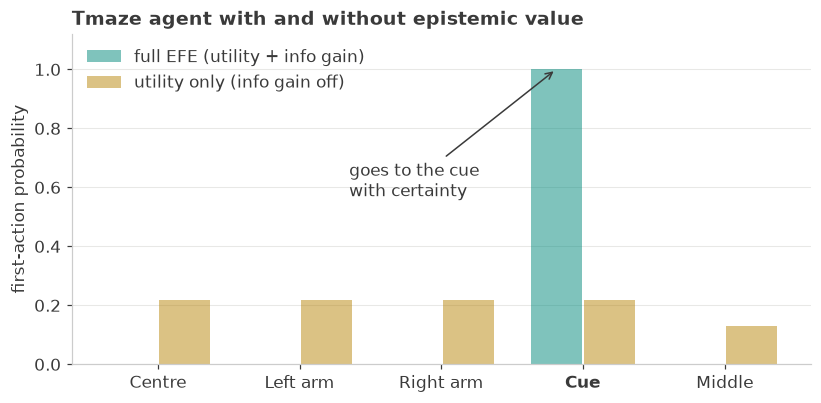

P(first action = cue): with info gain 1.000, without 0.217


In [4]:
actions = ["Centre", "Left arm", "Right arm", "Cue", "Middle"]
x = np.arange(5)

fig, ax = plt.subplots(figsize=(7.6, 3.8))
ax.bar(
    x - 0.19,
    first_action[True],
    0.36,
    color=TEAL,
    alpha=0.5,
    label="full EFE (utility + info gain)",
)
ax.bar(
    x + 0.19,
    first_action[False],
    0.36,
    color=AMBER,
    alpha=0.5,
    label="utility only (info gain off)",
)
ax.annotate(
    "goes to the cue\nwith certainty",
    xy=(3 - 0.19, first_action[True][3]),
    xytext=(1.35, 0.57),
    color=INK,
    arrowprops=dict(arrowstyle="->", color=INK, lw=1),
)
ax.set_xticks(x, actions)
ax.get_xticklabels()[CUE].set_fontweight("bold")
ax.set_ylim(0, 1.12)
ax.set_ylabel("first-action probability")
ax.set_title("Tmaze agent with and without epistemic value")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(
    f"P(first action = cue): with info gain {first_action[True][CUE]:.3f}, "
    f"without {first_action[False][CUE]:.3f}"
)

With the info-gain term the agent commits its whole first move to the cue; ablate that one
term and the cue becomes just another corridor (utility alone cannot distinguish looking from wandering). 
The same toggle works per modality block, and this exact behavior is pinned by the test suite at `pymdp` parity.


## 2. Continuous control

A 1-D cart on a hill (mountain-car-class, linear regime): gravity pulls it away from the
top everywhere except the summit — an unstable equilibrium at position 1.0. The robot gets
only a **noisy position measurement** each tick (no velocity), keeps a Gaussian belief
updated by a Kalman-style filter, and plans 4 ticks ahead over three thrust levels
{−1, 0, +1} with the same expected-free-energy planner as Section 1. Higher thrust is
noisier (engine vibration), so plans trade goal progress against the uncertainty they inject.


In [5]:
import hill_lg  # the runnable demo: a declared System driven through its faces

system, params = hill_lg.make_agent()
env, env_params = system.as_env(params)  # the same tensors, run forward

key = jax.random.PRNGKey(0)
key, k0 = jax.random.split(key)
obs, x_true = env.reset(k0, env_params, state={"state": jnp.zeros(2)})  # believe D; start at rest
priors = system.initial_priors(params)

pos, mu, sigma, thrust = [], [], [], []
first_tree = None  # per-policy EFE term tree from the first planning call (used in Section 3)
for _ in range(60):
    posterior, priors, action, tree = hill_lg.tick(system, params, obs, priors)
    if first_tree is None:
        first_tree = tree
    b = posterior["state"]
    cov = b.chol @ b.chol.T
    pos.append(float(x_true["state"][0]))
    mu.append(float(b.loc[0]))
    sigma.append(float(jnp.sqrt(cov[0, 0])))
    thrust.append(hill_lg.THRUSTS[int(action["a_state"])])
    key, k_env = jax.random.split(key)
    obs, x_true = env.step(k_env, x_true, action, env_params)

pos, mu, sigma, thrust = map(np.asarray, (pos, mu, sigma, thrust))
t = np.arange(60)

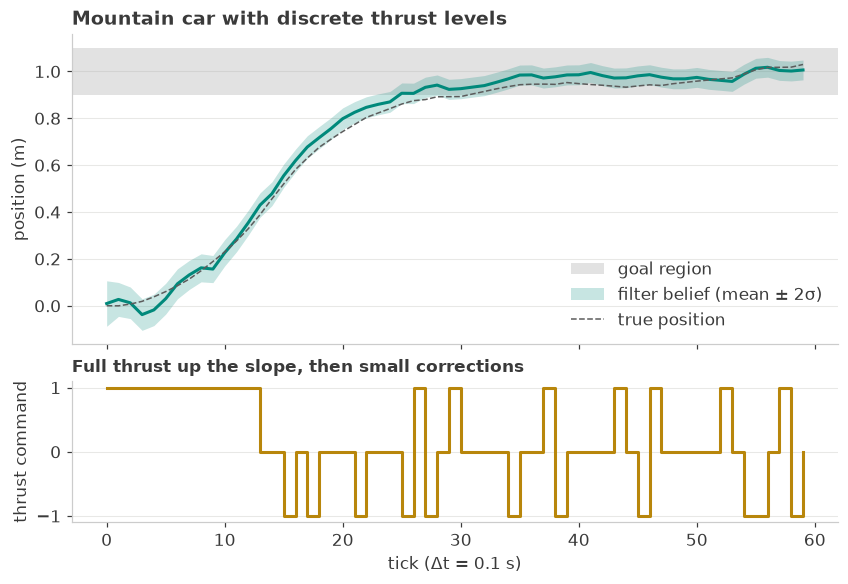

first tick in goal band: 31; in goal at end: True; filter σ(position) settles to ≈0.021 m (sensor noise σ = 0.05 m)


In [6]:
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(7.6, 5.2), sharex=True, height_ratios=[2.2, 1], constrained_layout=True
)

ax1.axhspan(
    hill_lg.GOAL_POS - hill_lg.GOAL_TOL[0],
    hill_lg.GOAL_POS + hill_lg.GOAL_TOL[0],
    color=GREY,
    alpha=0.35,
    lw=0,
    label="goal region",
)
ax1.fill_between(
    t,
    mu - 2 * sigma,
    mu + 2 * sigma,
    color=TEAL,
    alpha=0.22,
    lw=0,
    label="filter belief (mean ± 2σ)",
)
ax1.plot(t, mu, color=TEAL, lw=2)
ax1.plot(t, pos, color="#5C5C5C", lw=1, ls="--", label="true position")
ax1.set_ylabel("position (m)")
ax1.set_title("Mountain car with discrete thrust levels")
ax1.legend(loc="lower right", ncols=1)

ax2.step(t, thrust, where="post", color=AMBER, lw=2)
ax2.set_yticks([-1, 0, 1])
ax2.set_ylabel("thrust command")
ax2.set_xlabel("tick (Δt = 0.1 s)")
ax2.set_title("Full thrust up the slope, then small corrections", fontsize=11)
plt.show()

in_goal = np.abs(pos - hill_lg.GOAL_POS) <= hill_lg.GOAL_TOL[0]
print(
    f"first tick in goal band: {int(in_goal.argmax())}; "
    f"in goal at end: {bool(in_goal[-1])}; "
    f"filter σ(position) settles to ≈{sigma[-10:].mean():.3f} m "
    f"(sensor noise σ = 0.05 m)"
)

Everything in that loop — Gaussian beliefs, `predict`/`condition` filtering, the enumeration
planner, action selection — is the same machinery as the discrete agent, jitted end to end.
One thing is quietly missing though: the *epistemic* part of the objective barely
participated. Section 3 shows why that is a theorem, not a bug.


**The objective, spelled out.** The planner scores a thrust plan $\pi = (u_1,\dots,u_4)$
by pushing the belief through the declared dynamics — no observations enter imagination:

$$q_{t+1} = \mathcal{N}\!\big(F\mu_t + b_{u_t},\; F\Sigma_t F^\top + Q_{u_t}\big)$$

and summing, per step, the three registered terms (the leaves of `first_tree` above):

$$G(\pi) \;=\; \sum_t \underbrace{\mathrm{KL}\big(q_t \,\|\, C\big)}_{\text{risk}}
\;+\; \underbrace{H[q_t]}_{\text{uncertainty}}
\;-\; \underbrace{I(y_t; x_t)}_{\text{infogain}}
\;=\; -\sum_t \mathbb{E}_{q_t}[\ln C(x)] \;-\; \sum_t I(y_t; x_t)$$

with $C$ the Gaussian goal designation — so the first two terms together are literally the
expected (quadratic) goal cost, and the entropy is the price a plan pays for the uncertainty it
injects (here: process noise $Q_u$ grows with $|u|$ — engine vibration). That price is an
opt-in row, `uncertainty["state"]` $= H[q_t]$, declared on the System with
`terms=("uncertainty:state",)`. The last term is the information the expected position
reading $y_t$ carries about the state, $I(y_t; x_t) = H[q(y_t)] - H[y_t \mid x_t]$: the leaf
`infogain["position"]`, keyed by the observing channel and stored better-when-larger, so it
enters $G$ with a minus sign. `epistemic=False` ablates it per variable; Section 3 shows why
it barely matters here.

## 3. Linear-Gaussian VS mixture-model curiosity

Koudahl et al. (2021) proved that in linear-Gaussian systems the epistemic term of expected
free energy is **constant across policies**: every plan promises the same information, so
curiosity cannot influence which plan wins. In a *switching* (mixture) system that collapse
disappears — actions genuinely differ in how much uncertainty they leave behind.

First, the switching model itself; then the two curiosities side by side.

**The switching model, concretely.** One 1-D state, two dynamics modes — mode 0 drifts
left, mode 1 drifts right (two basins) — and the agent starts genuinely unsure which basin
it is in (a bimodal belief). Controls never move the state directly; they bias *which mode
fires* (commit ≈ 92 %, dither = 50/50). Below: the model at a glance, then what two plans do
to the belief itself — these are the actual mixture densities the planner pushes through the
rollout (exact grow → Runnalls-reduce, each step). Committing collapses the bimodality onto
the preferred basin; dithering leaves it split. That difference is exactly what the
belief's entropy measures (this model's `uncertainty` row: nothing observes its state, so it
has no information to gain) — compared next, and scored with bounds in Section 5.

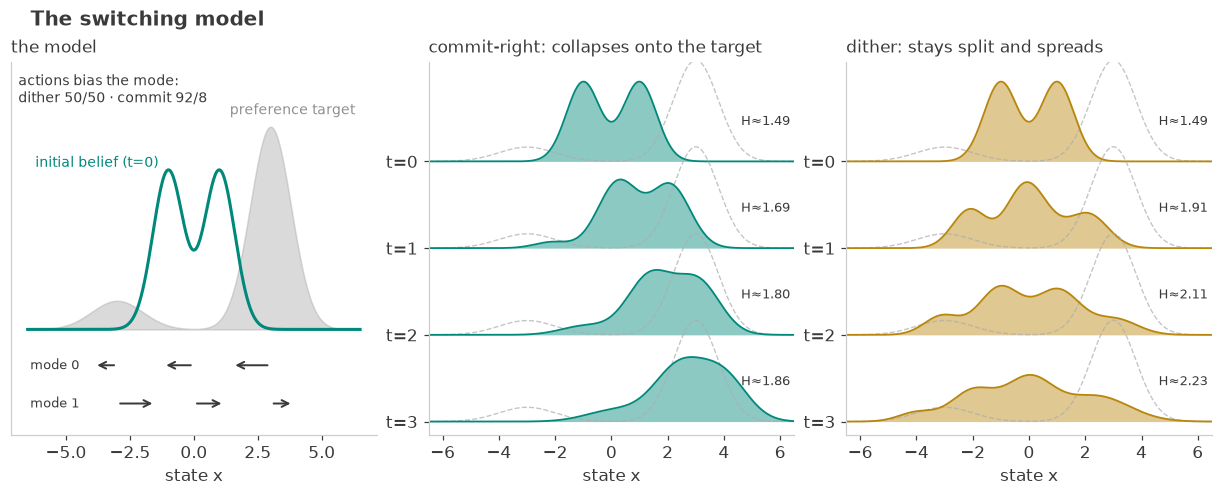

belief entropy after 3 steps, commit-right: [1.62, 2.11] nats (KT bounds)
belief entropy after 3 steps, dither: [1.98, 2.48] nats (KT bounds)


In [7]:
import hybrid_switching as hs

grid = np.linspace(-6.5, 6.5, 400)


def density(m):
    return np.exp(np.asarray(jax.vmap(m.log_prob)(jnp.asarray(grid)[:, None])))


def belief_ladder(label):  # beliefs at t=0..H under a named policy
    i = hs.POLICY_LABELS.index(label)
    return [hs.INIT_BELIEF, *hs.reduced_beliefs(hs.POLICIES[i])]


def entropy_mid(m):
    return float(m.entropy().midpoint)  # the belief entropy; -infogain in the tree


target_d = density(hs.TARGET)
ladders = {name: belief_ladder(name) for name in ("commit-right", "dither")}
dens = {name: [density(m) for m in ms] for name, ms in ladders.items()}
scale = 0.92 / max(d.max() for ds in dens.values() for d in ds)  # one scale everywhere

fig, (axa, axb, axc) = plt.subplots(1, 3, figsize=(11.0, 4.4), constrained_layout=True)
fig.suptitle(
    "The switching model",
    fontweight="bold",
    x=0.02,
    ha="left",
)

axa.fill_between(grid, 0.0, target_d, color=GREY, alpha=0.45)
axa.plot(grid, density(hs.INIT_BELIEF), color=TEAL, lw=2)
for x0 in (-3.0, 0.0, 3.0):  # one-step drift x -> Fx + b of each mode
    axa.annotate(
        "",
        xy=(0.9 * x0 - 1.2, -0.075),
        xytext=(x0, -0.075),
        arrowprops=dict(arrowstyle="->", color=INK, lw=1.3),
    )
    axa.annotate(
        "",
        xy=(0.9 * x0 + 1.2, -0.155),
        xytext=(x0, -0.155),
        arrowprops=dict(arrowstyle="->", color=INK, lw=1.3),
    )
axa.text(-6.4, -0.075, "mode 0", va="center", fontsize=8.5)
axa.text(-6.4, -0.155, "mode 1", va="center", fontsize=8.5)
axa.text(
    0.02,
    0.97,
    "actions bias the mode:\ndither 50/50 · commit 92/8",
    transform=axa.transAxes,
    va="top",
    fontsize=9,
)
axa.set_ylim(-0.22, 0.56)
axa.set_yticks([])
axa.grid(False)
axa.set_xlabel("state x")
axa.set_title("the model", fontsize=11, fontweight="normal")
axa.text(-6.2, 0.34, "initial belief (t=0)", color=TEAL, fontsize=9)
axa.text(6.3, 0.45, "preference target", color="#8F8F8F", fontsize=9, ha="right")


def ridgeline(ax, name, color, title):
    ms, ds = ladders[name], dens[name]
    horizon = len(ds) - 1
    for t, (m, d) in enumerate(zip(ms, ds, strict=True)):
        base = horizon - t  # t = 0 on top, later steps below
        ax.plot(grid, base + target_d * scale, color=GREY, lw=0.9, ls="--", alpha=0.7)
        ax.fill_between(grid, base, base + d * scale, color=color, alpha=0.45, lw=0)
        ax.plot(grid, base + d * scale, color=color, lw=1.2)
        ax.text(6.35, base + 0.42, f"H\u2248{entropy_mid(m):.2f}", ha="right", fontsize=8.5)
    ax.set_yticks([horizon - t for t in range(horizon + 1)], [f"t={t}" for t in range(horizon + 1)])
    ax.set_xlim(grid[0], grid[-1])
    ax.set_ylim(-0.15, horizon + 1.15)
    ax.grid(False)
    ax.set_xlabel("state x")
    ax.set_title(title, fontsize=11, fontweight="normal")


ridgeline(axb, "commit-right", TEAL, "commit-right: collapses onto the target")
ridgeline(axc, "dither", AMBER, "dither: stays split and spreads")
plt.show()

for name in ("commit-right", "dither"):
    h = ladders[name][-1].entropy()
    print(
        f"belief entropy after 3 steps, {name}: "
        f"[{float(h.lower):.2f}, {float(h.upper):.2f}] nats (KT bounds)"
    )

**The propagation, spelled out.** Each rung of those ladders is one line of algebra: the
control sets the mode weights $w_j(u) = P(\mathrm{mode}=j \mid u)$, every component of the
current belief is pushed through both mode dynamics (exact — momentarily $K\!\cdot\!M$
Gaussians), and Runnalls' KL-bound merge brings it back to the $K$-component budget:

$$q_{t+1} \;=\; \mathrm{reduce}_K\Big[\;\sum_j w_j(u_t)\!\int\!
\mathcal{N}\big(x' \mid F_j\,x + b_j,\, Q_j\big)\; q_t(x)\,dx\Big]$$

The objective is Section 2's risk + entropy sum (with no sensor, no information gain) — but
mixture entropies and KLs
have **no closed form**, so every term is a Kolchinsky–Tracey $[\mathrm{lower},
\mathrm{upper}]$ pair (Section 5's error bars), and the entropy now genuinely depends on
the plan: committing collapses the mixture, dithering doesn't. In the library this whole
loop is the System's transition closure — the ladders come from `System.predict_beliefs`,
the scores from `System.score_policies`.

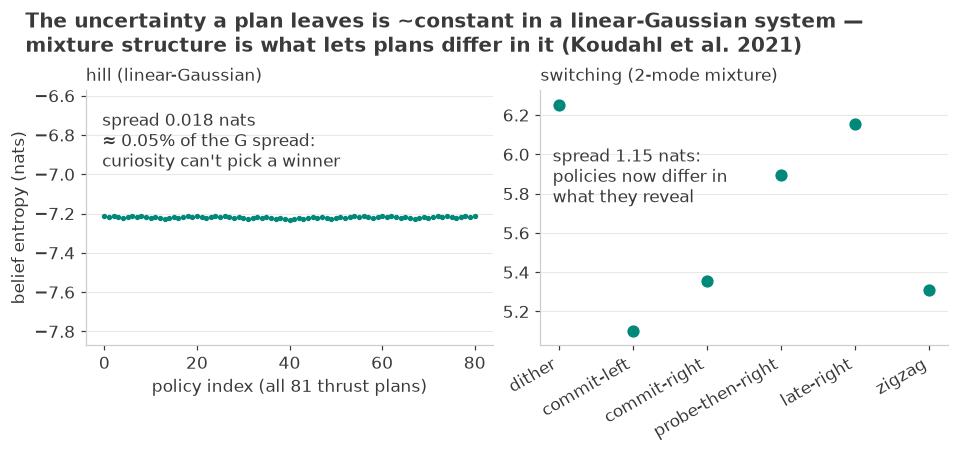

per-policy entropy spread — hill: 0.0178 nats over 81 policies; switching: 1.15 nats over 6 policies (~65x larger)
the hill's information gain about its state: spread 0.0007 nats


In [8]:
import hybrid_switching as hs

from hybrid_aif.objectives import total

# Left: the hill's belief entropy, one value per policy (from Section 2's first tick).
hill_ep = np.asarray(first_tree["uncertainty"]["state"].midpoint)  # sum over the plan of H[q_t]
hill_ig = np.asarray(first_tree["infogain"]["position"].midpoint)  # sum of I(y_t; x_t)
hill_g_spread = float(np.ptp(np.asarray(total(first_tree).midpoint)))

# Right: the switching demo's per-policy scores (grow-then-reduce mixture pipeline).
g_red, risk_red, ent_red = jax.jit(jax.vmap(hs.policy_scores))(hs.POLICIES)
g_exact, _, _ = jax.jit(jax.vmap(hs.policy_scores_exact))(hs.POLICIES)
switch_ep = np.asarray(ent_red.midpoint)

span = 1.3  # same vertical extent on both panels, so flat really looks flat
fig, (axl, axr) = plt.subplots(1, 2, figsize=(8.6, 4.0), constrained_layout=True)
fig.suptitle(
    "The uncertainty a plan leaves is ~constant in a linear-Gaussian system —\n"
    "mixture structure is what lets plans differ in it (Koudahl et al. 2021)",
    fontweight="bold",
    x=0.02,
    ha="left",
)

axl.plot(np.arange(81), hill_ep, ".", ms=5, color=TEAL)
axl.set_ylim(hill_ep.mean() - span / 2, hill_ep.mean() + span / 2)
axl.set_xlabel("policy index (all 81 thrust plans)")
axl.set_ylabel("belief entropy (nats)")
axl.set_title("hill (linear-Gaussian)", fontsize=11, fontweight="normal")
axl.annotate(
    f"spread {np.ptp(hill_ep):.3f} nats\n≈ {100 * np.ptp(hill_ep) / hill_g_spread:.2f}% "
    "of the G spread:\ncuriosity can't pick a winner",
    xy=(0.04, 0.70),
    xycoords="axes fraction",
    color=INK,
)

axr.plot(np.arange(6), switch_ep, "o", ms=7, color=TEAL)
axr.set_ylim(switch_ep.mean() - span / 2, switch_ep.mean() + span / 2)
axr.set_xticks(np.arange(6), hs.POLICY_LABELS, rotation=30, ha="right")
axr.set_title("switching (2-mode mixture)", fontsize=11, fontweight="normal")
axr.annotate(
    f"spread {np.ptp(switch_ep):.2f} nats:\npolicies now differ in\nwhat they reveal",
    xy=(0.03, 0.56),
    xycoords="axes fraction",
    color=INK,
)
plt.show()

ratio = np.ptp(switch_ep) / np.ptp(hill_ep)
print(
    f"per-policy entropy spread — hill: {np.ptp(hill_ep):.4f} nats over 81 policies; "
    f"switching: {np.ptp(switch_ep):.2f} nats over 6 policies (~{ratio:.0f}x larger)"
)
print(f"the hill's information gain about its state: spread {np.ptp(hill_ig):.4f} nats")

Left panel: 81 plans, one value for the uncertainty each plan leaves — the ~0.02-nat wiggle
(thrust-dependent process noise) is ~0.04% of the spread in the total objective, i.e.
decision-irrelevant — and the position reading's information gain about the state is flatter
still (printed above), as the theorem says. Right panel: give the world two dynamics modes and
the same term spans over a nat — *dither* leaves the most uncertainty, *commit-left* the least.
This is a core bet of the library: **hybrid mixture models are the minimal class where
continuous-state epistemic behavior exists**, and planning over them is what v0.1's mixture
machinery is for. Section 4 adds a sensor to a switching world, and the information gain itself
then picks the plan.

## 4. Closed-loop probing: reading a hidden current

Sections 2–3 *scored* plans open-loop. Now the loop is closed and the switch is genuinely
hidden. A boat holds station at a dock (`x = 0`) in an unknown current — a hidden two-state
mode — seeing only a noisy position each tick. It must *infer* the current by filtering the
mixture belief against evidence, and the hybrid epistemic term decides whether it bothers 
to find out.

**The two filtering messages.** Conditioning a mode-carried mixture on a reading does two
things. The continuous state takes the exact Gaussian-sum update (one Kalman `condition` per
component, reweighted by its evidence). The *discrete* mode updates from its slot bank — the
`mode_aligned` schedule keeps mode $j$'s mass in its own bank, so the boundary message is just
Bayes on the per-bank evidence:

$$q(\mathrm{mode}=j\mid y)\;\propto\;q(\mathrm{mode}=j)\;\,p(y\mid \mathrm{mode}=j),\qquad
p(y\mid\mathrm{mode}=j)=\!\!\sum_{k\,\in\,\text{bank }j}\!\!\frac{w_k}{W_j}\,
\mathcal{N}\!\big(y;\,H\mu_k+c,\;H\Sigma_k H^\top+R\big).$$

**Whether it probes** is the hybrid information gain. For the LG sensor over the mixture $x$,
the predictive reading $q(y)$ is itself a $K$-component mixture, so

$$\texttt{state\_info\_gain}=\underbrace{H[q(y)]}_{\text{KT bound pair}}
-\underbrace{\mathbb{E}_{q(x)}\,H[y\mid x]}_{\text{exact Gaussian}},$$

large exactly when the two mode-hypotheses sit far apart in $x$. *Anchoring* holds the dock
but drives both hypotheses to the same point (nothing to see); *drifting* lets the current
pull them apart. With info gain on, the planner values the drift — so the agent probes, the
reading resolves the current, and only then does it settle.

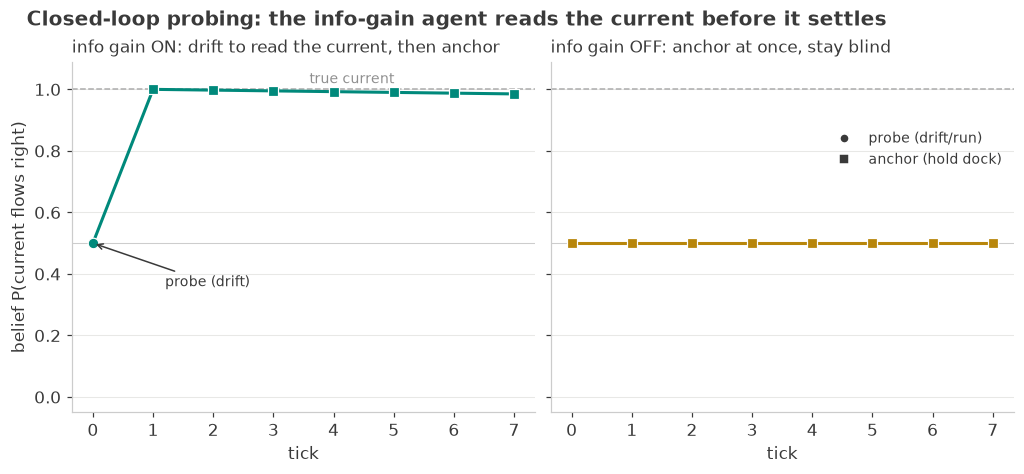

probing  (info gain on):  first action = drift; mode entropy 0.69 -> 0.08 nats
ablation (info gain off): first action = anchor; mode entropy 0.69 -> 0.69 nats (never resolves)


In [9]:
import switching_filter as sfl
from matplotlib.lines import Line2D

key_cl = jax.random.PRNGKey(0)
agent_ig, params_ig = sfl.make_agent(epistemic=True)
agent_ab, params_ab = sfl.make_agent(epistemic=False)
traj_probe = sfl.closed_loop(key_cl, agent_ig, params_ig, true_mode=1)
traj_ablate = sfl.closed_loop(key_cl, agent_ab, params_ab, true_mode=1)
ticks = np.arange(len(traj_probe.actions))

fig, (axp, axa) = plt.subplots(1, 2, figsize=(9.2, 4.2), sharey=True, constrained_layout=True)
fig.suptitle(
    "Closed-loop probing: the info-gain agent reads the current before it settles",
    fontweight="bold",
    x=0.02,
    ha="left",
)


def _panel(ax, traj, color, title):
    ax.axhline(1.0, color=GREY, ls="--", lw=1)  # the true current (mode 1, flows right)
    ax.axhline(0.5, color=GREY, lw=0.7, alpha=0.6)
    ax.plot(ticks, traj.mode_probs[:, 1], color=color, lw=2, zorder=2)
    for t in ticks:  # marker per tick: circle = probe (drift/run), square = anchor
        probe = int(traj.actions[t]) in sfl.PROBE_ACTIONS
        ax.scatter(
            [t],
            [traj.mode_probs[t, 1]],
            marker="o" if probe else "s",
            s=48,
            color=color,
            edgecolor="white",
            linewidth=0.8,
            zorder=3,
        )
    ax.set_xlabel("tick")
    ax.set_ylim(-0.05, 1.09)
    ax.set_title(title, fontsize=11, fontweight="normal")


_panel(axp, traj_probe, TEAL, "info gain ON: drift to read the current, then anchor")
_panel(axa, traj_ablate, AMBER, "info gain OFF: anchor at once, stay blind")
axp.set_ylabel("belief P(current flows right)")
axp.annotate(
    "probe (drift)",
    xy=(0, traj_probe.mode_probs[0, 1]),
    xytext=(1.2, 0.36),
    color=INK,
    fontsize=9,
    arrowprops=dict(arrowstyle="->", color=INK, lw=1),
)
axp.text(3.6, 1.02, "true current", color="#8F8F8F", fontsize=9)
_marks = [
    Line2D([], [], marker="o", ls="", color=INK, mec="white", label="probe (drift/run)"),
    Line2D([], [], marker="s", ls="", color=INK, mec="white", label="anchor (hold dock)"),
]
axa.legend(handles=_marks, loc="center right", fontsize=9, bbox_to_anchor=(1.0, 0.75))
plt.show()

_ent = lambda tr: (float(tr.mode_entropies[0]), float(tr.mode_entropies[-1]))
print(
    f"probing  (info gain on):  first action = {sfl.ACTION_LABELS[int(traj_probe.actions[0])]}; "
    f"mode entropy {_ent(traj_probe)[0]:.2f} -> {_ent(traj_probe)[1]:.2f} nats"
)
print(
    f"ablation (info gain off): first action = {sfl.ACTION_LABELS[int(traj_ablate.actions[0])]}; "
    f"mode entropy {_ent(traj_ablate)[0]:.2f} -> {_ent(traj_ablate)[1]:.2f} nats (never resolves)"
)

The info-gain agent drifts once (●), the reading collapses its uncertainty about the current,
and it anchors (■) for the rest of the episode — `P(current)` snaps from 50/50 to certain in a
single tick. Ablate the term and the agent anchors from the start (■ throughout): it keeps
station just as well but never learns the current, so its belief never leaves 50/50. That is
the closed-loop payoff of mixture *filtering* — not only carrying a mixture through imagination
(Section 3) but correcting it against evidence, and the epistemic drive that makes an agent act
to gather it. The mode posterior here matches an exact-enumeration filter to ~1e-9 (no
reduction) and keeps the exact policy ranking at the mode-aligned budget.

## 5. Error bars on the objective itself

Mixture quantities like the entropy above have **no closed form**. Instead of hiding a
biased point estimate, every term in `hybrid-aif` is computed as a Kolchinsky–Tracey
*bound pair* — the objective G arrives as a `[lower, upper]` interval, per policy. And
because beliefs are kept tractable by merging mixture components each step (Runnalls
reduction, 16 → 4 components here), we overlay the **exact enumeration** (no merging) to
check the shortcut: the policy ranking is identical.


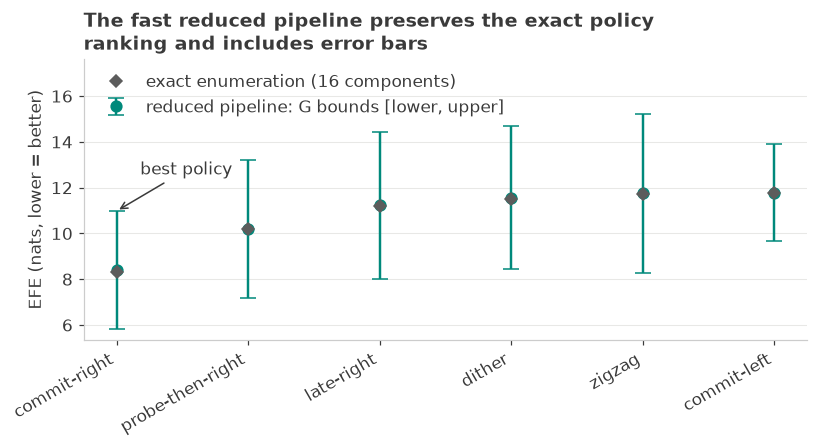

policy rankings agree, reduced vs exact: True
best policy: 'commit-right' (commit to the preferred mode; dithering is honestly rated worst)


In [10]:
order = np.argsort(np.asarray(g_red.midpoint))
mid = np.asarray(g_red.midpoint)[order]
lo = np.asarray(g_red.lower)[order]
hi = np.asarray(g_red.upper)[order]
exact = np.asarray(g_exact.midpoint)[order]
names = [hs.POLICY_LABELS[i] for i in order]
xs = np.arange(len(names))

fig, ax = plt.subplots(figsize=(7.6, 4.2))
ax.errorbar(
    xs,
    mid,
    yerr=[mid - lo, hi - mid],
    fmt="o",
    ms=7,
    color=TEAL,
    ecolor=TEAL,
    elinewidth=1.6,
    capsize=5,
    label="reduced pipeline: G bounds [lower, upper]",
)
ax.plot(xs, exact, "D", ms=6, color="#5C5C5C", zorder=3, label="exact enumeration (16 components)")
ax.set_xticks(xs, names, rotation=30, ha="right")
ax.set_ylim(top=float(hi.max()) + 2.4)  # headroom so the legend clears the error bars
ax.set_ylabel("EFE (nats, lower = better)")
ax.set_title(
    "The fast reduced pipeline preserves the exact policy \nranking and includes error bars"
)
ax.annotate(
    "best policy",
    xy=(0, hi[0]),
    xytext=(0.18, hi[0] + 1.6),
    color=INK,
    arrowprops=dict(arrowstyle="->", color=INK, lw=1),
)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

rank_red = np.argsort(np.argsort(np.asarray(g_red.midpoint)))
rank_ex = np.argsort(np.argsort(np.asarray(g_exact.midpoint)))
print(f"policy rankings agree, reduced vs exact: {bool((rank_red == rank_ex).all())}")
print(
    f"best policy: {hs.POLICY_LABELS[int(np.asarray(g_red.midpoint).argmin())]!r} "
    "(commit to the preferred mode; dithering is honestly rated worst)"
)

Error bars here are *bounds, not variance*: the true G of each policy provably lies inside
its bar. The grey diamonds (exact, exponentially many components) sit inside every interval
and induce the same ordering — which is all a planner needs. You get the speed of the
reduced pipeline and a certificate that it didn't change the decision.


## 6. Speed check vs `pymdp`

Same T-maze model tensors, same algorithms (mean-field fixed-point state inference;
exhaustive policy enumeration under expected free energy), both libraries jitted JAX on the
same CPU — so this measures *implementation overhead*, not algorithmic advantage. Outputs
are asserted equal before any timing. The batched rows vmap one full tick
(state + policy inference) over independent agents; on the `pymdp` side we vmap its
functional core directly (exactly what its `Agent` class does internally), which is the
fairest comparison we could construct.

One-shot timings on microsecond workloads are not stable: OS scheduling and cache state
swing a single median 2–4× run to run, in either direction. So this block pushes 25
measurement rounds through the same jitted functions and reports each row as
median [min–max]. Full methodology, a `--quick` smoke mode, and a `--rounds` flag live in
`examples/benchmark_pymdp.py`.

In [11]:
import benchmark_pymdp as bench

print(bench.machine_report())
rows = bench.run_benchmarks_rounds(rounds=25, reps=10, batch_sizes=(1, 10, 100))
print()
print(bench.format_variance_table(rows))

machine: macOS-15.7.5-arm64-arm-64bit / arm64; backend: cpu; jax 0.11.0, pymdp 1.0.3



median [min-max] us across 25 measurement rounds
benchmark (T-maze, CPU)                       hybrid-aif             pymdp   ratio
----------------------------------------------------------------------------------
state inference (FPI, 16 sweeps)              17 [16-18]        16 [16-17]   1.05x
policy inference (25 policies, H=2)           53 [47-62]        37 [34-41]   1.42x
policy inference, metrics=False               50 [45-55]        37 [35-40]   1.35x
full tick, vmap x 1 agent                     62 [60-79]        55 [51-72]   1.13x
full tick, vmap x 10 agents                  99 [95-116]       93 [83-104]   1.07x
full tick, vmap x 100 agents               337 [329-346]     390 [378-402]   0.86x
----------------------------------------------------------------------------------
ratio = ratio of medians (< 1 means hybrid-aif is faster)


Takeaways: state inference is at parity. The default policy row pays for assembling the
full per-term, per-block metrics tree with interval bounds — the material Sections 3–5 are
made of — and that price is now a visible toggle with a printed cost: the `metrics=False`
row scores the *same* posterior (to float reassociation) with G accumulated directly in the
scan carry, and runs at `pymdp` parity; the small residual is the G bound-pair, a quantity
`pymdp` does not carry. The [min–max] columns are why this table reports spreads — a single
run at this scale can mislead by 2–4× in either direction. Batch scaling is the headline:
100 agents cost a single-digit multiple of one agent, not 100×, on both sides — the
`vmap`-first design `hybrid-aif` inherits deliberately from `pymdp` and builds on.

## 7. Parameter learning

Everything above ran on *fixed* generative tensors. v0.3 makes them posterior objects: a
declaration slot holds either a point value or the **distribution over its own parameters**
— a `ConditionalDirichlet` where a CPD table would sit, an `InverseGamma` where an LG noise
`R_chol` would sit. The distributional form makes a slot learnable; wherher a given tick
actually updates is a per-slot **rate** (`0.0` freezes losslessly; a traced rate schedules 
learning inside `scan`). One new face joins the loop, before `act` so planning sees fresh counts:

```python
beliefs, detail = system.infer_states(params, obs, priors, detail=True)
params          = system.learn(params, obs, beliefs, prev_beliefs, prev_action, detail=detail)
action, q_pi, _ = system.act(key, params, beliefs)
```

**The discrete update is the textbook conjugate count,** responsibility-weighted by the
state posterior, while inference averages over the parameters properly (the digamma table
$\mathbb{E}[\log A]$, not $\log \mathbb{E}[A]$ — a deliberate, documented divergence from
`pymdp`'s mean-sync):

$$\alpha \;\leftarrow\; \alpha + \mathrm{lr}\cdot\big(\mathrm{onehot}(o)\otimes q(s_1)\otimes\cdots\big).$$

And the recovery test needs no external fixture, because a System is its own environment:
`as_env(params, param_key=key)` **draws the true table from the agent's own prior**, runs
it forward, and the agent learns back a truth it has never seen — the model closing its own
loop.


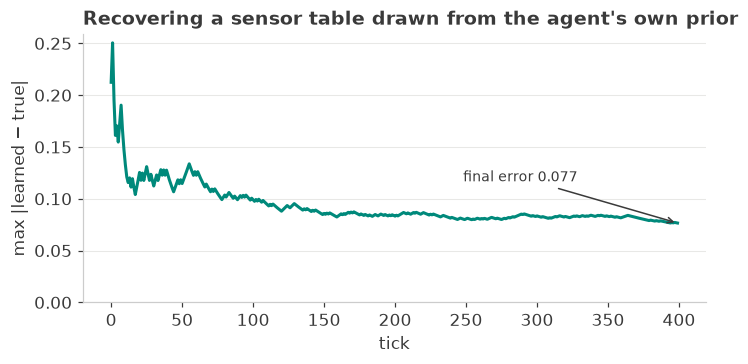

true table (drawn, never shown to the agent):
 [[0.791 0.001]
 [0.209 0.999]]


In [12]:
import noise_learning as nl

err, true_table = nl.recover_table(jax.random.PRNGKey(0), n_ticks=400)
fig, ax = plt.subplots(figsize=(6.4, 3.2), constrained_layout=True)
ax.plot(np.asarray(err), color=TEAL, lw=2)
ax.set_title("Recovering a sensor table drawn from the agent's own prior")
ax.set_xlabel("tick")
ax.set_ylabel("max |learned − true|")
ax.set_ylim(0, None)
ax.annotate(
    f"final error {float(err[-1]):.03f}",
    xy=(len(err) - 1, float(err[-1])),
    xytext=(len(err) * 0.62, float(err[0]) * 0.55),
    color=INK,
    fontsize=9,
    arrowprops=dict(arrowstyle="->", color=INK, lw=1),
)
plt.show()
print("true table (drawn, never shown to the agent):\n", np.asarray(true_table).round(3))

**The continuous half is the coverage story in miniature.** A robot's position fix is
sharp in some map cells and loose in others. Below, a `cell` modality reports which cell
the robot is in (95% reliable), and a `pose` modality observes a latent position whose
noise is **per-cell and unknown** — an `InverseGamma` posterior in the noise slot, starting
ignorant at $\sigma_0 = 0.6$ for both cells. Each tick's sufficient statistic is the
responsibility-weighted expected residual scatter

$$q(j)\;\Big[\big(y - H\mu_j - c\big)\big(y - H\mu_j - c\big)^{\!\top} + H\Sigma_j H^{\!\top}\Big],$$

with two details doing the work: the $H\Sigma H^\top$ term charges the *pose posterior's 
own uncertainty* to the state rather than the sensor (drop it and the learned noise biases 
low — that's a test, not a comment), and the responsibilities $q(j)$ come from the 
**pre-reduction mixture** that `infer_states(detail=True)` surfaces — the mode-conditional
pairing that the mixture-budget reduction would otherwise destroy. Inference meanwhile
consumes the noise posterior by its **expected precision** ($R_\text{eff} = \beta/\alpha$
per dimension), the mean-field-correct substitution and the LG twin of the digamma table.
The `decay` knob is anchored forgetting: relax toward a constitutive prior, wash out the
early biased-estimate phase, and trade tracking speed against steady-state variance (the
measured baselines live in `test_lg_noise_learning`). Inverse-Wishart (full covariance) and
matrix-normal–inverse-Wishart (learn the sensor *map* jointly with its noise — which needs a
calibrated co-sensor: with a once-observed latent, $(H, R)$ share a likelihood ridge) ship
behind the same slot.

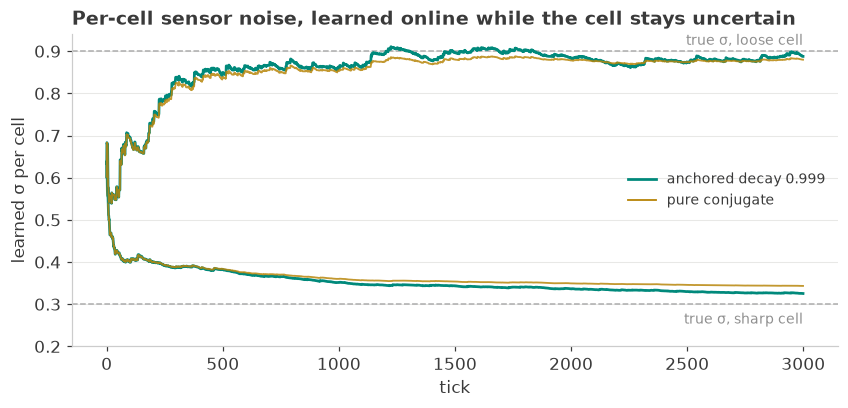

final σ (decay): [0.325 0.888]  true: (0.3, 0.9)


In [13]:
run_decay = nl.run(jax.random.PRNGKey(7), n_ticks=3000, decay=0.999)
run_conj = nl.run(jax.random.PRNGKey(7), n_ticks=3000, decay=None)
ticks = np.arange(run_decay.sigma.shape[0])

fig, ax = plt.subplots(figsize=(7.6, 3.6), constrained_layout=True)
ax.set_title("Per-cell sensor noise, learned online while the cell stays uncertain")
for j, true in enumerate(nl.TRUE_SIGMA):
    ax.axhline(true, color=GREY, ls="--", lw=1)
    ax.plot(ticks, np.asarray(run_decay.sigma[:, j]), color=TEAL, lw=1.8)
    ax.plot(ticks, np.asarray(run_conj.sigma[:, j]), color=AMBER, lw=1.2, alpha=0.85)
ax.text(
    ticks[-1],
    nl.TRUE_SIGMA[0] - 0.02,
    "true σ, sharp cell",
    color="#8F8F8F",
    fontsize=9,
    ha="right",
    va="top",
)
ax.text(
    ticks[-1],
    nl.TRUE_SIGMA[1] + 0.015,
    "true σ, loose cell",
    color="#8F8F8F",
    fontsize=9,
    ha="right",
)
ax.set_ylim(0.2, None)
ax.set_xlabel("tick")
ax.set_ylabel("learned σ per cell")
from matplotlib.lines import Line2D

ax.legend(
    handles=[
        Line2D([], [], color=TEAL, lw=1.8, label="anchored decay 0.999"),
        Line2D([], [], color=AMBER, lw=1.2, label="pure conjugate"),
    ],
    loc="center right",
    fontsize=9,
)
plt.show()
print("final σ (decay):", np.asarray(run_decay.sigma[-1]).round(3), " true:", nl.TRUE_SIGMA)

Both cells' noise separates from one shared ignorant prior while the agent never sees the
true cell — the 95%-reliable report plus the pose evidence itself does the credit
assignment. The amber pure-conjugate run carries its early biased phase in the average
forever; the teal anchored-decay run forgets it. This is the mechanism the coverage agent's
`p_fix` swap runs on: per-cell fix quality, learned on-robot, feeding the same planner that
Sections 1–4 exercised.

## 8. The model as a document and its description length

Everything above was declared in Python. A model is also a **document**: `describe(system,
params)` writes it as a description (variables, factor records, clamps, configuration) and
`build(document)` reads it back, bitwise. Once a model is a document it can be compared with
another one by **what it costs to write down**, in nats.

The comparison here is between two models of one record. A scripted agent runs the Section 1
T-maze world for 120 episodes: centre, cue, centre, middle, then the arm the cue named. Model
**A** is the world's model: the cue reads the context. Model **B** is a simpler guess: the cue
reads the location alone, so in B the cue carries no news and the arm's reward is a coin flip.
The two documents differ in one parent list.

Each model is priced by its **description length** over the record, in two parts: the nats
to state the model, plus the nats to state the record given the model.
`description_length(document, replay=...)` gives both. The model part is a graph code over
the structure plus each family's parametric complexity at resolution `n`, the amount of data
that table is judged against in the record: an observation table at the record's ticks, a
transition at the ticks with a step, an initial prior at the episodes (the tables are point
values, so they have no prior link to price). The data part is the sum of `replay`'s per-tick
free energies over the record, replayed under the model `build` makes of the same document.
This replay does not learn, so the family links are what pays for the parameters. A model
that learns along its replay pays for them in its free energies instead, the early ticks
costing more while it learns, and `description_length` then leaves the family links out
rather than charge twice (Section 11).

In [14]:
import model_document as mdoc

doc_a, (system_a, params_a), same = mdoc.round_trip(*mdoc.make_model(cue_reads_context=True))
doc_b, _, _ = mdoc.round_trip(*mdoc.make_model(cue_reads_context=False))
print("bitwise round trip:", same)
print("A's cue record:", doc_a["factors"]["cue"]["likelihood"])
print("B's cue record:", doc_b["factors"]["cue"]["likelihood"])

result = mdoc.compare(n_episodes=120)
first = mdoc.crossover(result)
for label in ("A", "B"):
    print(
        f"model {label}: {result.model_nats[label][-1]:6.1f} nats to state, "
        f"{result.data_nats[label][-1]:6.1f} nats of record (120 episodes)"
    )
print(f"A's two-part total is lower from episode {first} on")

bitwise round trip: True
A's cue record: {'family': 'ConditionalCategorical', 'parents': ['location', 'context'], 'parameters': {'log_table': 'A_cue'}}
B's cue record: {'family': 'ConditionalCategorical', 'parents': ['location'], 'parameters': {'log_table': 'A_cue'}}


model A:  540.3 nats to state,  103.6 nats of record (120 episodes)
model B:  507.5 nats to state,  175.2 nats of record (120 episodes)
A's two-part total is lower from episode 48 on


**The two parts, spelled out.** For a record $o_{1:T}$ and a model $M$,

$$L(o_{1:T}, M) \;=\; \underbrace{L(M)}_{\texttt{description\_length}} \;+\;
\underbrace{\sum_t F_t}_{\texttt{replay(...).free\_energy}}, \qquad
F_t \;\ge\; -\ln \tilde p_t(o_t).$$

Here $\tilde p_t$ is the predictive the model carries into tick $t$: its previous posterior,
pushed through the transition. Each $F_t$ bounds the code length of the tick's observations
under that predictive. That is the prequential code length $-\ln p(o_t \mid o_{<t}, M)$
whenever the previous posterior was exact, and the bound is tight when the mean-field
posterior is the exact one. It is here: the location is observed without noise, so only the
context is uncertain, and the two quantities coincide (the test suite pins the sum against an
enumerated evidence). The model part grows with the record too: each column of a table with
$L$ levels adds $\tfrac{L-1}{2}\ln\tfrac{n}{2\pi}$, with $n$ the data that table is judged
against, plus a constant, the log volume of the
simplex under its Jeffreys prior. A's cue table has twice B's columns, so A pays a little more
each time the record grows. A, in return, pays heavily for the record only on the rare
episodes where the arm surprises it: a wrong cue, or a null outcome at the right arm, each
about 2% of episodes.

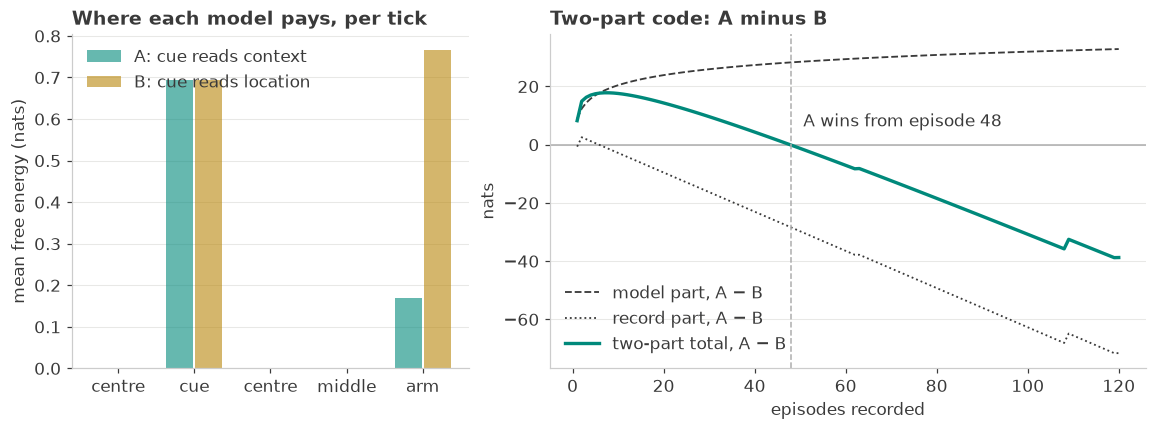

In [15]:
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10.4, 3.8), width_ratios=[1, 1.5], constrained_layout=True
)

ticks = np.arange(mdoc.TICKS_PER_EPISODE)
ax1.bar(
    ticks - 0.19, result.per_tick["A"], 0.36, color=TEAL, alpha=0.6, label="A: cue reads context"
)
ax1.bar(
    ticks + 0.19, result.per_tick["B"], 0.36, color=AMBER, alpha=0.6, label="B: cue reads location"
)
ax1.set_xticks(ticks, ["centre", "cue", "centre", "middle", "arm"])
ax1.set_ylabel("mean free energy (nats)")
ax1.set_title("Where each model pays, per tick")
ax1.legend(loc="upper left")

eps = result.episodes
model_gap = result.model_nats["A"] - result.model_nats["B"]
data_gap = result.data_nats["A"] - result.data_nats["B"]
ax2.axhline(0.0, color=GREY, lw=1)
ax2.plot(eps, model_gap, color=INK, lw=1.2, ls="--", label="model part, A − B")
ax2.plot(eps, data_gap, color=INK, lw=1.2, ls=":", label="record part, A − B")
ax2.plot(eps, model_gap + data_gap, color=TEAL, lw=2.2, label="two-part total, A − B")
ax2.axvline(first, color=GREY, lw=1, ls="--")
ax2.annotate(
    f"A wins from episode {first}",
    (first, 0),
    xytext=(8, 12),
    textcoords="offset points",
    color=INK,
)
ax2.set_xlabel("episodes recorded")
ax2.set_ylabel("nats")
ax2.set_title("Two-part code: A minus B")
ax2.legend(loc="lower left")
plt.show()

Both models pay the same `ln 2` at the cue tick: before the reading, a left or a right cue
is equally likely under each. The difference comes at the arm. A has read the context off the
cue and expects the reward, while B still faces a coin flip. Stating A costs more, by one
parent and five more table columns, and that cost grows slowly with the record. The record
part falls by about 0.6 nats per episode. The jumps upward are the episodes where the cue
was wrong and A was confidently surprised. A null outcome at the arm surprises A just as much,
but it surprises B equally, so it leaves no jump in the gap. The two-part total crosses zero once the
record is long enough for the cue's extra column to pay for itself. Every number in this
comparison came from the documents, rebuilt by `build`: a model described once can be priced,
replayed and compared by a program that never sees its Python.

## 9. Composition: one mind by `merge()`, two minds by `couple()`

Two robots share a corridor of five cells with a charging dock at each end, and the job is
one robot per dock. Each robot's model is a small `System` of its own: where it is, where the
other robot is (modelled as a random walk), exact sensors for both positions, and a
preference over a `status` reading: *apart on the docks* +4, *both on one dock* −2, anything
else 0. Facing a robot it models as a random walk, each robot wants a dock.

The same two declarations compose two ways:

- **Merged** (`merge()`): one mind given both bodies. `ObservationLink`s point each model's
  sensors at the robots' own position factors, and the result is one `System` that plans over
  *both* robots' moves and acts on a whole joint policy (`act(..., mode="policy")`). It is
  stepped against the corridor as its own world (`as_env`).
- **Coupled** (`couple()`): two minds, each in its own perception–action loop with a shared
  world. `Wire`s bind each mind to the corridor through its Markov blanket: its sensors read the corridor's positions and status, its move writes to the
  corridor. Nothing connects the two minds except the corridor. `hybrid_aif.composition.run`
  steps them, as in `examples/hide_and_seek.ipynb`.

The test is the symmetric start: both robots in the middle cell, each dock two moves away for
either robot.

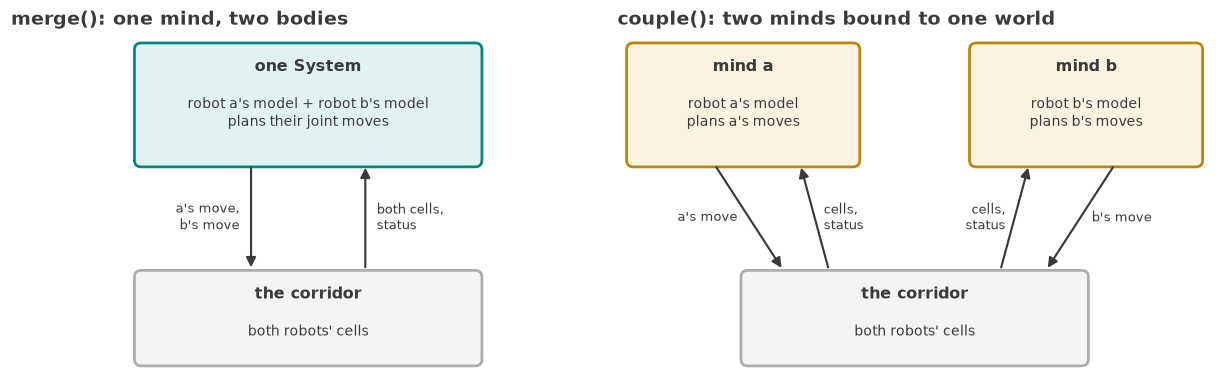

In [16]:
# how each composition is wired: the merged mind holds both bodies; each coupled mind meets
# the world only through its own sensors and its own move (its Markov blanket)
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch


def box(ax, x, y, w, h, title, lines, edge, fill):
    ax.add_patch(
        FancyBboxPatch(
            (x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.06", fc=fill, ec=edge, lw=1.8
        )
    )
    ax.text(x + w / 2, y + h - 0.12, title, ha="center", va="top", fontsize=10.5, weight="bold")
    ax.text(x + w / 2, y + h - 0.42, lines, ha="center", va="top", fontsize=9, linespacing=1.4)


def arrow(ax, start, end, label, side, color=INK):
    ax.add_patch(
        FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=13, lw=1.4, color=color)
    )
    mid = ((start[0] + end[0]) / 2, (start[1] + end[1]) / 2)
    ax.text(
        mid[0] + side,
        mid[1],
        label,
        fontsize=8.5,
        ha="left" if side > 0 else "right",
        va="center",
        color=color,
    )


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 3.4), constrained_layout=True)
for ax in (ax1, ax2):
    ax.set_xlim(-0.1, 5.1)
    ax.set_ylim(0, 3.0)
    ax.axis("off")

ax1.set_title("merge(): one mind, two bodies")
box(
    ax1,
    1.0,
    1.85,
    3.0,
    1.05,
    "one System",
    "robot a's model + robot b's model\nplans their joint moves",
    TEAL,
    "#E0F2F1",
)
box(ax1, 1.0, 0.1, 3.0, 0.8, "the corridor", "both robots' cells", GREY, "#F4F4F2")
arrow(ax1, (2.0, 1.85), (2.0, 0.92), "a's move,\nb's move", -0.1)
arrow(ax1, (3.0, 0.92), (3.0, 1.85), "both cells,\nstatus", 0.1)

ax2.set_title("couple(): two minds bound to one world")
box(ax2, 0.0, 1.85, 2.0, 1.05, "mind a", "robot a's model\nplans a's moves", AMBER, "#FBF3E0")
box(ax2, 3.0, 1.85, 2.0, 1.05, "mind b", "robot b's model\nplans b's moves", AMBER, "#FBF3E0")
box(ax2, 1.0, 0.1, 3.0, 0.8, "the corridor", "both robots' cells", GREY, "#F4F4F2")
arrow(ax2, (0.75, 1.85), (1.35, 0.92), "a's move", -0.1)
arrow(ax2, (1.75, 0.92), (1.5, 1.85), "cells,\nstatus", 0.08)
arrow(ax2, (4.25, 1.85), (3.65, 0.92), "b's move", 0.1)
arrow(ax2, (3.25, 0.92), (3.5, 1.85), "cells,\nstatus", -0.08)
plt.show()

In [17]:
import compose_minds as cm

for claim, ok in cm.identity_check().items():
    print(f"merged System vs longhand declaration, {claim}: bitwise {ok}")
counts = cm.policy_counts()
print(
    f"policies scored per tick (horizon 2): merged {counts['merged']} joint, "
    f"each coupled mind {counts['coupled']} of its own"
)

robot, robot_params = cm.robot(*cm.SYMMETRIC)
obs = {"me_obs": jnp.asarray(2), "other_obs": jnp.asarray(2), "status": jnp.asarray(2)}
q_robot, _ = robot.infer_policies(robot_params, robot.infer_states(robot_params, obs)[0])
plans = [tuple(p) for p in np.asarray(robot.policies(robot_params))[:, :, 0].tolist()]
print(
    "one coupled mind at the middle cell: P(left, left) = "
    f"{float(q_robot.probs[plans.index((0, 0))]):.3f}, "
    f"P(right, right) = {float(q_robot.probs[plans.index((2, 2))]):.3f}"
)

merged System vs longhand declaration, static fields: bitwise True
merged System vs longhand declaration, parameter arrays: bitwise True
merged System vs longhand declaration, beliefs: bitwise True
merged System vs longhand declaration, policy scores: bitwise True
policies scored per tick (horizon 2): merged 81 joint, each coupled mind 9 of its own


one coupled mind at the middle cell: P(left, left) = 0.455, P(right, right) = 0.455


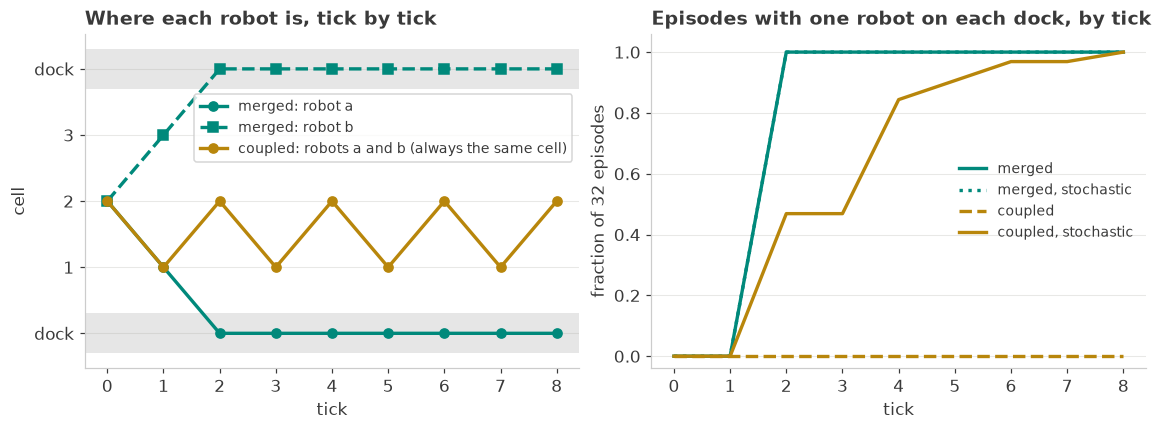

coupled, stochastic: one robot on each dock in 32 of 32 episodes within 8 ticks, 15 of them at tick 2


merged, acting on marginals: one robot on each dock in 0 of 32 episodes (deterministic); stochastic 12 of 32 at tick 2, 32 within 8 ticks
start (2, 2): one robot on each dock, merged at tick 2, coupled (deterministic) never
start (1, 2): one robot on each dock, merged at tick 2, coupled (deterministic) at tick 2


In [18]:
key = jax.random.PRNGKey(0)
merged_path = cm.merged_episode(key, cm.SYMMETRIC)
coupled_path = cm.coupled_episode(key, cm.SYMMETRIC)
curves = {
    "merged": cm.split_by_tick(cm.merged_episode, 32, start=cm.SYMMETRIC)[0],
    "merged, stochastic": cm.split_by_tick(
        cm.merged_episode, 32, start=cm.SYMMETRIC, selection="stochastic"
    )[0],
    "coupled": cm.split_by_tick(cm.coupled_episode, 32, start=cm.SYMMETRIC)[0],
    "coupled, stochastic": cm.split_by_tick(
        cm.coupled_episode, 32, start=cm.SYMMETRIC, selection="stochastic"
    )[0],
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.4, 3.8), constrained_layout=True)
ticks = np.arange(len(merged_path[0]))
ax1.axhspan(-0.3, 0.3, color=GREY, alpha=0.3, lw=0)
ax1.axhspan(cm.N - 1.3, cm.N - 0.7, color=GREY, alpha=0.3, lw=0)
ax1.plot(ticks, merged_path[0], color=TEAL, lw=2.2, marker="o", label="merged: robot a")
ax1.plot(ticks, merged_path[1], color=TEAL, lw=2.2, marker="s", ls="--", label="merged: robot b")
ax1.plot(
    ticks,
    coupled_path[0],
    color=AMBER,
    lw=2.2,
    marker="o",
    label="coupled: robots a and b (always the same cell)",
)
ax1.set_yticks(range(cm.N), ["dock", "1", "2", "3", "dock"])
ax1.set_xlabel("tick")
ax1.set_ylabel("cell")
ax1.set_title("Where each robot is, tick by tick")
ax1.legend(loc="upper right", bbox_to_anchor=(1.0, 0.84), fontsize=9, frameon=True)

styles = {
    "merged": (TEAL, "-"),
    "merged, stochastic": (TEAL, ":"),
    "coupled": (AMBER, "--"),
    "coupled, stochastic": (AMBER, "-"),
}
for label, curve in curves.items():
    color, ls = styles[label]
    ax2.plot(ticks, curve, color=color, ls=ls, lw=2.2, label=label)
ax2.set_xlabel("tick")
ax2.set_ylabel("fraction of 32 episodes")
ax2.set_ylim(-0.04, 1.06)
ax2.set_title("Episodes with one robot on each dock, by tick")
ax2.legend(loc="center right", fontsize=9)
plt.show()

first = cm.split_by_tick(cm.coupled_episode, 32, start=cm.SYMMETRIC, selection="stochastic")[1]
print(
    f"coupled, stochastic: one robot on each dock in {int((first >= 0).sum())} of 32 episodes "
    f"within 8 ticks, {int((first == 2).sum())} of them at tick 2"
)
marginal = cm.split_by_tick(cm.merged_episode, 32, start=cm.SYMMETRIC, mode="marginal")[0]
stochastic_marginal = cm.split_by_tick(
    cm.merged_episode, 32, start=cm.SYMMETRIC, selection="stochastic", mode="marginal"
)[0]
print(
    f"merged, acting on marginals: one robot on each dock in {int(marginal[-1] * 32)} of 32 "
    f"episodes (deterministic); "
    f"stochastic {int(stochastic_marginal[2] * 32)} of 32 at tick 2, "
    f"{int(stochastic_marginal[-1] * 32)} within 8 ticks"
)
for start in (cm.SYMMETRIC, cm.ASYMMETRIC):
    m = cm.split_tick(*cm.merged_episode(key, start))
    c = cm.split_tick(*cm.coupled_episode(key, start))
    c = "never" if c is None else f"at tick {c}"
    print(f"start {start}: one robot on each dock, merged at tick {m}, coupled (deterministic) {c}")

**Reading the figure.** The left panel is one episode: each robot's cell at each tick. The
merged mind (teal) sends robot a left and robot b right, and both are docked at tick 2. The
two coupled minds (amber) compute the same thing from the same view, so the two robots are in
the same cell at every tick and one line shows both. They are not failing to find the docks;
they are deadlocked. From the middle, each mind wants a dock and values the two equally (its
plans to the left dock and to the right dock hold 0.455 of its policy posterior each), and
both break the tie the same way: both step left. At cell 1, side by side, each expects the
other, which it models as a random walk, might reach the left dock too, so that dock now
risks *both on one dock* (−2), and the right dock is three moves away, beyond the two-step
horizon. The plans that stay off the left dock all score the same, three of the five begin
with a step right, and both robots step back to the middle. Then the cycle repeats.

The right panel counts, over 32 episodes, how many have one robot on each dock by each tick.
The merged mind gets there at tick 2, the earliest possible, in all 32, under deterministic or
stochastic selection. Deterministic coupled minds never get there. Coupled minds under
stochastic selection break the symmetry by chance: all 32 within 8 ticks, 15 of them at tick 2.

Three more things the printout shows. The merged `System` is the longhand declaration, compared
bitwise. The one mind has to act on a whole joint policy: its two dock assignments score the
same, so each robot's own first-step marginal is 50/50 between left and right, and acting on
those marginals (`act`'s default for discrete controls) it deadlocks as the coupled pair does
(deterministic: none of 32; stochastic: 12 of 32 at tick 2). And the difference needs the
symmetry: move one robot a cell toward a dock (start `(1, 2)`) and both compositions reach
one robot per dock at tick 2. The price of the one mind is the joint policy set, 81 plans a
tick at horizon 2 against 9 for each coupled mind, growing as the product of the robots'
moves. `examples/hide_and_seek.ipynb` is the competitive coupled case, a prey and a predator
with opposed objectives.

## 10. Planning that expects to observe: a detour for a better fix

Section 3 ended on a theorem: on a linear-Gaussian model the information-gain term is the
same for every plan. The reason is mechanical. With a constant observation noise the Kalman
covariance recursion ignores the controls, whether the belief is only predicted or also
conditioned on the observations a plan expects, so no plan can promise to leave the agent
better informed than another.

Two things change that, and both are now declared rather than hand-built. First, a
**noise map**: the observation noise depends on where the state is (`GridNoiseMap`, an
`R_chol` read off a smooth grid by interpolation). Second, **`planning_belief="posterior"`**:
the planner carries a second belief alongside the predictive one, conditioned at every step
on the observation it expects there, with the noise the map gives at that step's mean.
Targets and risk still read the predictive belief. Only the fix's information-gain leaf reads
the conditioned one, so its value at each step is the information that step's fix will add
given the plan's earlier ones. Under the default, `planning_belief="prior"`, the same leaf reads
the predictive belief: the map enters it too, at the predicted mean, but each step's fix is
counted as though no earlier fix had been taken.

The task: a rover drives from a waypoint at (−1, 0) to a dock at (1, 0). Its position fix is
precise only near a survey beacon at (0, 0.6), off to one side of the straight route: the map
gives σ near 0.6 far from the beacon, about 0.46 where the straight route passes closest, and
about 0.06 at the beacon (printed below). The gradient planner chooses an open-loop plan of
eight velocity steps. We plan the same model under two objectives. The first expects no
observation: under `"prior"`, with the information gain switched off (`epistemic=False`), it
charges the entropy of the predictive belief, the `uncertainty` row
(`terms=("uncertainty:position",)`). The second is the fix's information gain under
`"posterior"`. This is plan scoring, not a closed loop: the figure shows the plans each
objective prefers, and the uncertainty each plan is expected to leave.

fix σ: 0.60 far from the beacon, 0.46 where the straight route passes closest, 0.063 at the beacon


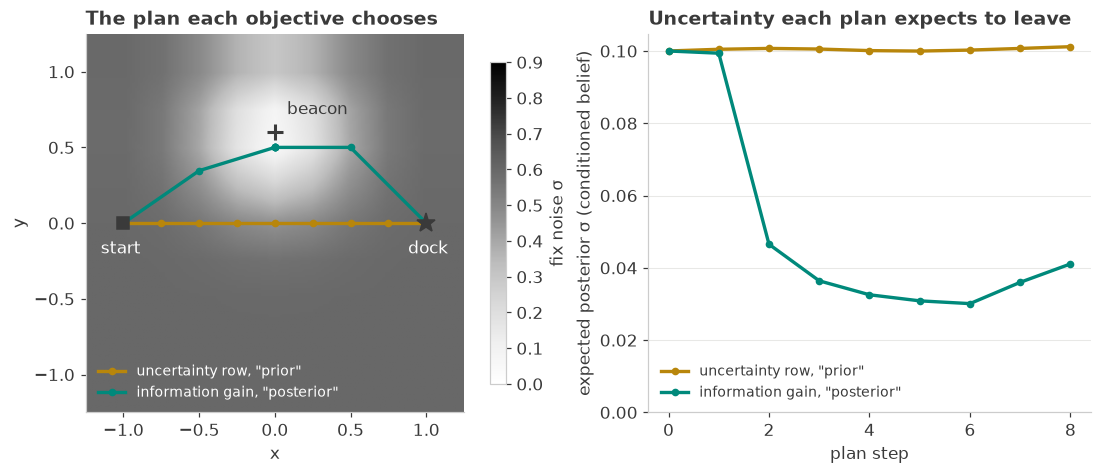

G of each plan (nats; rows: the objective it is scored under)
             prior plan  posterior plan
      prior     -12.796         -12.796
  posterior      -0.246          -3.556


In [19]:
import sensor_detour as sd

detour = sd.compare()
sig = sd.map_sigmas()
print(
    f"fix σ: {sig['far']:.2f} far from the beacon, {sig['route']:.2f} where the straight "
    f"route passes closest, {sig['beacon']:.3f} at the beacon"
)

# the map itself, evaluated where the planner reads it
view = (-1.25, 1.25)  # beyond the grid the map holds its edge values
fine = np.linspace(*view, 141)
gx, gy = np.meshgrid(fine, fine, indexing="ij")
chols = sd.sensor_map()(jnp.asarray(np.stack([gx.ravel(), gy.ravel()], -1)))
sigma_map = np.asarray(chols[:, 0, 0]).reshape(gx.shape)

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10.4, 4.2), width_ratios=[1.15, 1], constrained_layout=True
)
im = ax1.imshow(
    sigma_map.T,
    origin="lower",
    extent=(*view, *view),
    cmap="Greys",
    vmin=0.0,
    vmax=0.9,
    interpolation="bilinear",
)
fig.colorbar(im, ax=ax1, shrink=0.85, label="fix noise σ")
styles = {
    "prior": (AMBER, 'uncertainty row, "prior"'),
    "posterior": (TEAL, 'information gain, "posterior"'),
}
for b, (color, label) in styles.items():
    track = detour.tracks[b]
    ax1.plot(track[:, 0], track[:, 1], "-o", color=color, lw=2.2, ms=4, label=label)
ax1.plot(*sd.START, "s", color=INK, ms=8)
ax1.plot(*sd.DOCK, "*", color=INK, ms=13)
ax1.plot(*sd.BEACON, "+", color=INK, ms=11, mew=2)
ax1.annotate("start", sd.START, (-1.15, -0.2), color="white")
ax1.annotate("dock", sd.DOCK, (0.88, -0.2), color="white")
ax1.annotate("beacon", sd.BEACON, (0.08, 0.72), color=INK)
ax1.set_title("The plan each objective chooses")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.grid(False)
ax1.legend(loc="lower left", fontsize=9, labelcolor="white")

steps = np.arange(len(detour.sds["posterior"]))
for b, (color, label) in styles.items():
    ax2.plot(steps, detour.sds[b], "-o", color=color, lw=2.2, ms=4, label=label)
ax2.set_title("Uncertainty each plan expects to leave")
ax2.set_xlabel("plan step")
ax2.set_ylabel("expected posterior σ (conditioned belief)")
ax2.set_ylim(0, None)
ax2.legend(fontsize=9)
plt.show()

print("G of each plan (nats; rows: the objective it is scored under)")
print(f"{'':>11}{'prior plan':>12}{'posterior plan':>16}")
for s in ("prior", "posterior"):
    row = [detour.G[(s, b)] for b in ("prior", "posterior")]
    print(f"{s:>11}{row[0]:12.3f}{row[1]:16.3f}")

Under the predictive belief's entropy the planner drives straight to the dock, and the table
shows why: the two plans score the same to the printed precision (−12.796 each), so nothing in
that objective prefers the beacon. A belief no fix conditions grows by the process noise alone,
which is the same on every route. Under the conditioned belief's information gain the plan
reaches the beacon's side, (0, 0.5), in two steps, holds there for four, and then turns for the
dock. Read on the conditioned belief (the right panel reads both plans there), it arrives
expecting σ ≈ 0.04 instead of ≈ 0.10, and its own objective prefers it by about 3.3 nats.
Both plans end at the dock; what the detour buys is a sharper belief when the rover gets there.
The two rows of the table are different objectives, so compare plans within a row, not across
rows. The default
information gain under `"prior"` reads the map as well, so it too prefers a route past the
beacon, but it scores each step's fix on the predictive belief, as though the fixes before it
had not been taken. The noise is read at each step's predicted mean, the extended Kalman
filter's convention: the map's variation across the belief's own spread is ignored, which is
the documented first version.

## 11. Structure learning: a model that grows a state when the world shows it something new

Every model above had its number of states fixed when it was declared. A robot that meets a
new kind of thing cannot have declared a state for it. Here a stream of 2-D readings arrives
one per tick from four clusters, and at tick 250 a **fifth cluster** starts to appear among
them. Each model is one categorical factor `z` whose levels emit the reading through a Gaussian
(`gaussian_emission`) that learns its offset and noise, run through the same `infer_states`
and `learn` every tick. Three models see the same stream:

- **Growing**: a cap of 16 levels with one live, its weights carrying a growth propensity
  `α = 1`. When no live level explains a point better than an unused level at its prior
  would, by a margin of `log α`, `learn` wakes a dead level and seeds it from that point
  alone. Its starting level is declared as if woken, at weight `α`, the prior pseudo-count a
  woken level gets.
- **Fixed, 4 levels**: the right number of states until tick 250. To be generous, each
  level starts on the first point of one of the four clusters.
- **Fixed, 5 levels**: the right number for the whole stream, started the same way, including
  on the first point of the cluster that has not arrived yet, which no model running online
  could know. It is the reference for what knowing the answer in advance is worth.

The score is each model's **description length** over the stream, in nats, as in Section 8:
what the model costs to state plus what the stream costs to state under it,
`description_length(model, replay=...)`. The model part is what the declaration says before
any data that the stream puts to use: its graph, and its prior link, how far the declared
prior sits from the family's uninformative base, for every level the model uses, a level the
growing model wakes included, since the woken level starts from what the declaration holds
there. That is where the fixed models pay for starting on the clusters. The data
part is the free energy summed along a `replay` with learning on: each point is scored under
the model as learned from the points before it, so the data part also pays for each parameter
as it is learned, and the family links are left out. A point's share of the data part is
close to its **surprise**, `−log p(y)` under the model's posterior predictive before it learns
from the point. The figure shows both: each point's surprise above, the description length
below. The growing model's predictive puts no mass on a level it has not woken yet (no
`α / (n + α)` term for a new level), so a novel point is charged to it in full: a
conservative convention, not a flattering one.

Each model runs at the emission prior strength that suited it better, judged by surprise, of
the two tried on these streams: 0.1 for the growing model, 1 for the fixed ones. At 0.1 a fixed
model's broad young levels soak up the other clusters' tails; at 1 the growing model is the
worse one on average, more surprised than the fixed four-level model (4.77 against 4.63 nats
per point from tick 300, over the ten streams below), though per stream it is mixed: worse on
six of the ten, better on four.

**The two rules, spelled out.** With $\ell_j(y)$ the Student-t posterior predictive
log-density of the point $y$ under level $j$, and $\ell_\varnothing(y)$ the same under the
prior, a tick wakes the first dead level when

$$\max_{j\ \text{live}} \ell_j(y) \;<\; \ell_\varnothing(y) + \log\alpha .$$

The woken level takes the point outright and its weight starts at $\alpha$ plus one count;
otherwise the point is shared among live levels by its posterior, as in any conjugate
update. A merge of levels $i$ and $j$ is kept when

$$\log p(\text{data} \mid i \cup j \text{ pooled}) \;\ge\; \log p(\text{data} \mid i,\ j \text{ separate}),$$

summed over every table the factor is an axis of: the emission's matrix-normal
inverse-Wishart evidence, and the Dirichlet evidence of the weights. The merged level keeps
both levels' data; the other goes back to dead.

         growing: 4.28 nats per point from tick 300, 5 live levels at the end
 fixed, 4 levels: 4.72 nats per point from tick 300, 4 live levels at the end
 fixed, 5 levels: 4.27 nats per point from tick 300, 5 live levels at the end
the new cluster's first point (tick 254): surprise 39.1 nats under the growing model, live levels 4 → 5


reduce on the growing model: live levels after each call [5]


α = 20: 16 live levels, after each reduce call [12, 6, 5, 5]


         growing: description length    64 (model; prior link  47) +   1668 (data) =   1732 nats
 fixed, 4 levels: description length   168 (model; prior link 151) +   1696 (data) =   1864 nats
 fixed, 5 levels: description length   207 (model; prior link 190) +   1603 (data) =   1810 nats


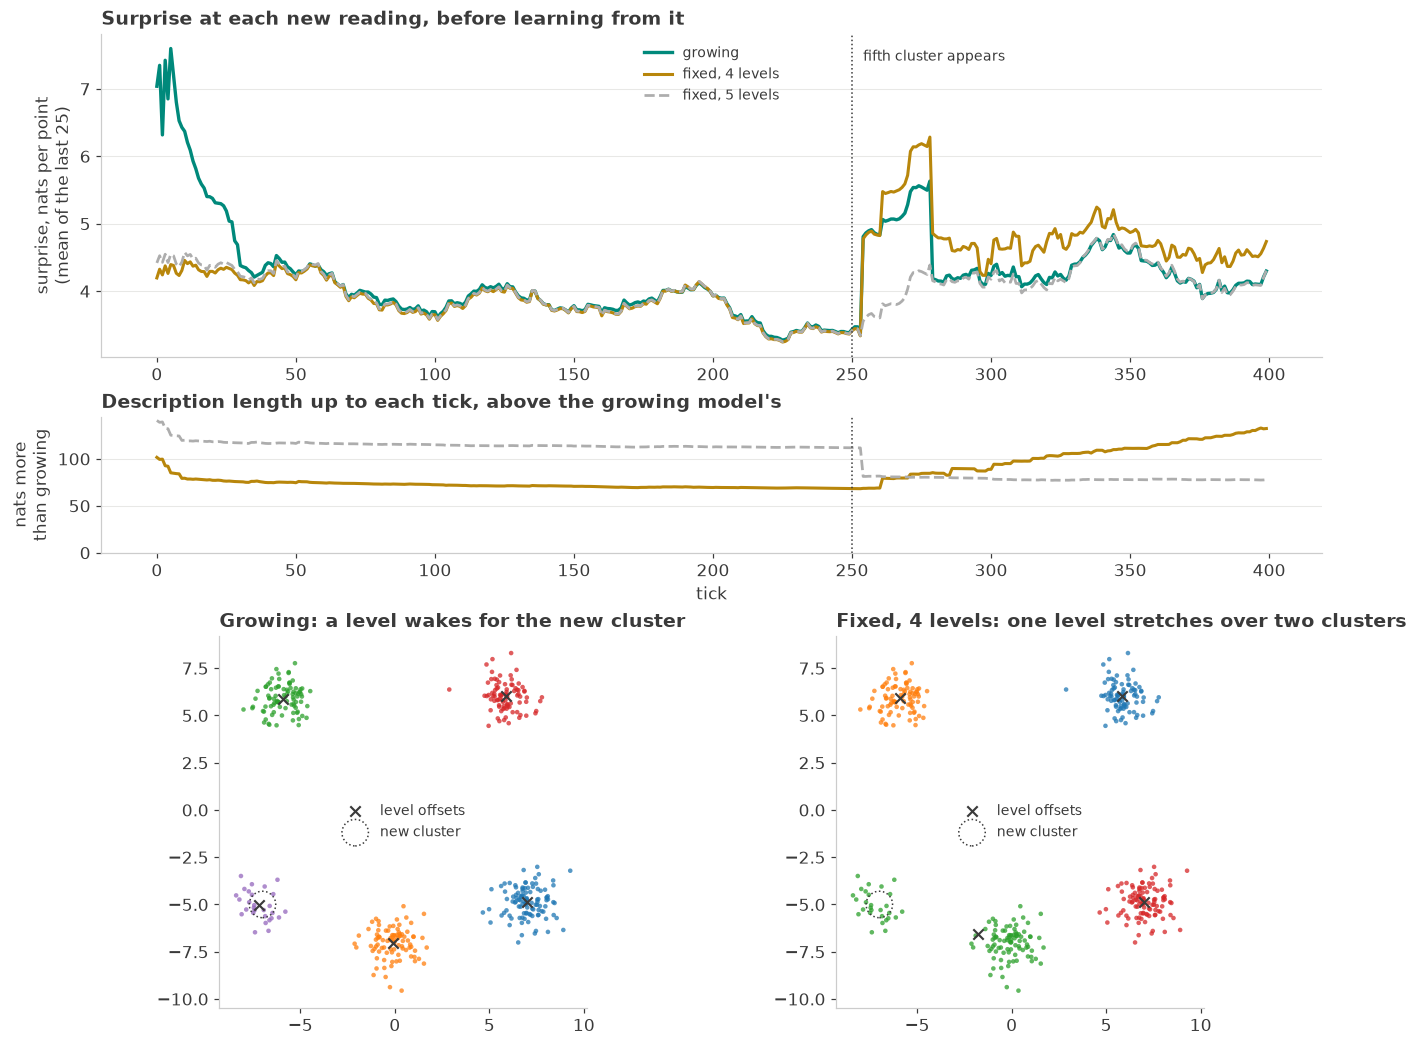

In [20]:
import growing_mixture as gm

points, labels = gm.stream(n=400, seed=0)
results = gm.compare(points, labels)
for name, r in results.items():
    print(
        f"{name:>16}: {gm.settled_surprise(r):.2f} nats per point from tick 300, "
        f"{gm.live_count(r.learned)} live levels at the end"
    )
grown = results["growing"]
first_new = int(np.flatnonzero(labels == 4)[0])
print(
    f"the new cluster's first point (tick {first_new}): surprise "
    f"{grown.surprise[first_new]:.1f} nats under the growing model, live levels "
    f"{grown.live[first_new - 1]} → {grown.live[first_new]}"
)
_, counts = gm.reduce_until_stable(grown.system, grown.learned, grown.prior)
print(f"reduce on the growing model: live levels after each call {counts}")
eager_sys, eager_prior = gm.growing_model(alpha=20.0)
eager, _, eager_live = gm.run_stream(eager_sys, eager_prior, points)
_, eager_counts = gm.reduce_until_stable(eager_sys, eager, eager_prior)
print(f"α = 20: {gm.live_count(eager)} live levels, after each reduce call {eager_counts}")

lengths = gm.description_lengths(points, labels)
for name, x in lengths.items():
    t = x.total
    print(
        f"{name:>16}: description length {t.model:5.0f} (model; prior link {t.parameters:3.0f}) "
        f"+ {t.data:6.0f} (data) = {t.total:6.0f} nats"
    )

fig = plt.figure(figsize=(12.0, 9.4), constrained_layout=True)
grid = fig.add_gridspec(3, 2, height_ratios=[1.0, 0.42, 1.15])
ax = fig.add_subplot(grid[0, :])
ticks = np.arange(len(points))
styles = {
    "growing": dict(color=TEAL, lw=2.2),
    "fixed, 4 levels": dict(color=AMBER, lw=2.0),
    "fixed, 5 levels": dict(color=GREY, lw=1.8, ls="--"),
}
for name, r in results.items():
    ax.plot(ticks, gm.rolling(r.surprise), label=name, **styles[name])
ax.axvline(gm.ARRIVAL, color=INK, lw=1, ls=":")
ax.text(gm.ARRIVAL + 4, ax.get_ylim()[1] * 0.97, "fifth cluster appears", fontsize=9, va="top")
ax.set_ylabel("surprise, nats per point\n(mean of the last 25)")
ax.set_title("Surprise at each new reading, before learning from it")
ax.legend(loc="upper center", fontsize=9)

gap = fig.add_subplot(grid[1, :], sharex=ax)
base = lengths["growing"].running
for name in ("fixed, 4 levels", "fixed, 5 levels"):
    gap.plot(ticks, lengths[name].running - base, **styles[name])
gap.axvline(gm.ARRIVAL, color=INK, lw=1, ls=":")
gap.set_ylim(bottom=0)
gap.set_xlabel("tick")
gap.set_ylabel("nats more\nthan growing")
gap.set_title("Description length up to each tick, above the growing model's")

levels_cmap = plt.get_cmap("tab10")
for col, name, title in (
    (0, "growing", "Growing: a level wakes for the new cluster"),
    (1, "fixed, 4 levels", "Fixed, 4 levels: one level stretches over two clusters"),
):
    ax = fig.add_subplot(grid[2, col])
    r = results[name]
    assigned = gm.assign(r.system, r.learned, points)
    ax.scatter(*points.T, c=levels_cmap(assigned % 10), s=9, alpha=0.75, lw=0)
    _, means = gm.levels(r.learned)
    ax.scatter(*means.T, marker="x", s=46, color=INK, lw=1.4, label="level offsets")
    ax.scatter(
        *gm.NEW.T, s=300, facecolors="none", edgecolors=INK, lw=1, ls=":", label="new cluster"
    )
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.legend(loc="center", fontsize=9)
plt.show()

The growing model's description length starts lowest and stays lowest. Its model part is 64
nats: its structure, and the declared start of each level the stream has it use, one at the
origin to begin with and four woken later, 9 nats each. The fixed models' model parts are 168 nats for four levels and
207 for five, mostly the prior links of their placed levels (151 and 190). The fixed models
code the first points more cheaply, having been told where the clusters are: over the first
thirty ticks the growing model is about 0.8 nats per point more surprised while it wakes a
level for each cluster, which takes six ticks. From tick 35 to 250 the three gain at the same
rate, within 0.04 nats per point of each other. Through this four-cluster phase the five-level
model is the most expensive of the three: it has paid for a level the stream does not use
yet, and at tick 250 it is 43 nats above the four-level model.

Then the fifth cluster appears. Its first point costs the growing model 39 nats, because no
live level comes near it (the raised stretch in the upper panel, and the drop in the
five-level model's lead at tick 254 in the lower); that same point wakes a
level, the cluster's second point costs 8.6 nats under a level that has seen one point, and the
level sharpens from there. The five-level model, started on that very point, pays about 9.
From tick 300 the growing model gains 4.28 nats per point, the five-level model 4.27, and the
four-level model 4.72. The four-level model cannot add a state, so one level, the one on the
cluster at (0, −7), takes all of the new points: its offset slides towards them and its noise
stretches across both, and the model is more surprised than the growing one on the old
clusters' points as well as the new one's. The five-level model passes it at tick 271. At tick
400 the totals are 1,732 nats for the growing model, 1,810 for the five-level one and 1,864
for the four-level one. The five-level model codes the data best (1,603 nats against 1,668),
but its head start costs more to state than it saves.

The same holds over ten streams (`tests/test_demo_growing_mixture.py`): the growing model's
description length is the lowest at every tick on every stream, by at least 42 nats, and the
five-level model is behind the four-level one at tick 250 and ahead by the end. Per point from
tick 300, the growing model is less surprised than the fixed four-level model on all ten, by
0.29 to 0.55 nats, and within 0.04 nats of the five-level model on all ten, a little behind it
on average (about 0.01). What growth buys is not a better model than the right fixed one: it is
not having to know the number of states, or where they are, before the data shows them, and
not paying to state them in advance. Reduction is the clean-up: on this stream the growing
model holds no redundant level, and one reduce call changes nothing.

**Growing too eagerly, then reducing.** The growth propensity sets how readily a level is
woken. At `α = 20` the margin is `log 20 ≈ 3` nats in favour of a new level, so the model
wakes levels for points its live levels already explain fairly well, and the cap of 16 fills.
Reduction undoes it: each `System.reduce` call merges the candidate pairs whose pooled
evidence is no lower than their separate evidence, and repeated calls settle on the five levels
the stream needs, then change nothing more; on all ten streams the eager model comes back to
five.

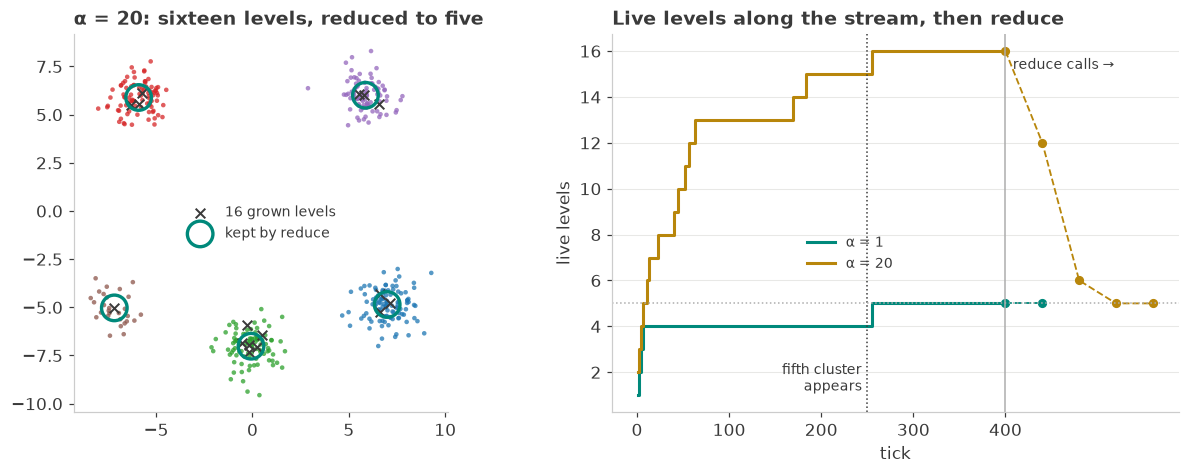

In [21]:
eager_reduced, eager_counts = gm.reduce_until_stable(eager_sys, eager, eager_prior)
grown_counts = gm.reduce_until_stable(grown.system, grown.learned, grown.prior)[1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 4.2), constrained_layout=True)
assigned = gm.assign(eager_sys, eager_reduced, points)
ax1.scatter(*points.T, c=levels_cmap(assigned % 10), s=9, alpha=0.75, lw=0)
_, grown_means = gm.levels(eager)
ax1.scatter(*grown_means.T, marker="x", s=40, color=INK, lw=1.3, label="16 grown levels")
_, kept = gm.levels(eager_reduced)
ax1.scatter(*kept.T, s=280, facecolors="none", edgecolors=TEAL, lw=2.2, label="kept by reduce")
ax1.set_title("α = 20: sixteen levels, reduced to five")
ax1.set_aspect("equal")
ax1.grid(False)
ax1.legend(loc="center", fontsize=9)

n = len(points)
for live, counts, color, label in (
    (grown.live, grown_counts, TEAL, "α = 1"),
    (eager_live, eager_counts, AMBER, "α = 20"),
):
    ax2.step(np.arange(1, n + 1), live, where="post", color=color, lw=2, label=label)
    xs = n + 40 * np.arange(len(counts) + 1)
    ax2.plot(xs, [live[-1], *counts], "o--", color=color, ms=5, lw=1.2)
ax2.axvline(n, color=GREY, lw=1)
ax2.axvline(gm.ARRIVAL, color=INK, lw=1, ls=":")
ax2.text(gm.ARRIVAL - 6, 1.2, "fifth cluster\nappears", fontsize=9, ha="right")
ax2.text(n + 8, gm.K_MAX - 0.3, "reduce calls →", fontsize=9, va="top")
ax2.axhline(len(gm.CENTRES), color=GREY, lw=1, ls=":")
ax2.set_xticks(np.arange(0, n + 1, 100))
ax2.set_xlabel("tick")
ax2.set_ylabel("live levels")
ax2.set_title("Live levels along the stream, then reduce")
ax2.legend(loc="center", bbox_to_anchor=(0.42, 0.42), fontsize=9)
plt.show()

The same two steps run inside `learn` on a schedule (`System(reduction_period=...)`), and
`examples/gameworld_growth.py` runs them on a control task: a Gameworld-style plane, four
moves, reward for moving towards the nearest food, with the model growing from one level.
Over 2,000 ticks and three seeds, a reduction every 250 learn calls reaches about 0.9 reward
per tick on two seeds with 7 to 9 live levels, against 14 to 16 without reduction, whose best
seed ends at 0.94 and whose other falls back to 0.56 after peaking at 0.90. Reducing every 100
calls learns on one of the three. The third seed learns under none of the three, so the task
is fragile at this budget, and the schedule is a setting to choose with care rather than a
settled finding.

## What exists today

**In v0.1 (all of it exercised above, 300+ tests green):**

- Discrete engine at exact `pymdp` parity: state inference, EFE policy scoring, planning, learning updates
- The `System` abstraction — one object is both agent and environment (forward = env, backward = inference)
- Continuous linear-Gaussian filtering + planning through the same planner interface
- Mixture (GMM) beliefs with grow-then-reduce rollouts and ranking-fidelity checks
- Per-term / per-block EFE metrics trees with interval bounds; per-block ablation toggles (EFE ⊃ KL-control ⊃ expected utility)
- Batched multi-agent inference via `vmap` at ground level

**In v0.2 (landed, and already running above): the hybrid `System`** — typed factor
families (Categorical, linear-Gaussian, mixture) declared behind the same faces, so a single
agent plans across the discrete–continuous boundary: Sections 2–5 run through
`System.score_policies` and `System.predict_beliefs`, both demo agents *are* declared
Systems (at parity with their former hand-rolled versions), and hierarchical conditional
priors (`D_deps`) let a higher-level factor set a lower level's initial beliefs. Section 4
adds mixture *filtering* against evidence — mode-aligned Gaussian-sum conditioning with the
hybrid information-gain term — so a closed-loop agent infers a hidden mode and probes to
resolve it.

**In v0.3 (landed, Section 7): parameter learning** — polymorphic
declaration slots (a slot holds a point value or the posterior over its own parameters),
`System.learn` with per-slot rates and anchored forgetting, conjugate families for tabular
CPDs and LG observation noise/heads (Dirichlet, inverse-Gamma/-Wishart, matrix-normal–IW),
transition novelty in the planning objective, draw-truth-from-prior recovery via
`as_env(param_key=...)`, and the `infer_states` detail channel surfacing pre-reduction
responsibilities.

**Since then (Sections 8–11, and much the notebook does not show):** composition by
`merge()` into one declaration (v0.5, v0.12), the model as a document with a bitwise
`describe`/`build` round trip and recorded-trace `replay` (v0.8, description 0.3 in v0.12),
the description length and closed-form evidence (v0.13), planning that expects to observe
(v0.13), and structure learning: a Gaussian emission over categorical parents, levels that are
born and merged, a lagged datum. Beside them, and beyond this notebook: the CEM, sophisticated
and habit planners, control and action nodes, the amortized tier (recognition, the
imagination trainer, the R-AIF replication) and the registry of objective rows
(`examples/objectives_a_la_carte.ipynb`). `docs/capabilities.md` is the complete, current list.

**Read more:** `README.md` (project spec) · `docs/project-brief.md` (architecture and
build status) · `docs/de-risk-report.md` (the mixture/entropy-bound machinery, with
citations) · `docs/capabilities.md` (everything, current) · `examples/` (the runnable scripts behind
Sections 2–11).